In [3]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/bmaryam/anly530-obesity-research-dataset/ObesityDataSet_raw_and_data_sinthetic.csv
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__notebook__.ipynb
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__output__.json
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results__.html
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__resultx__.html
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/custom.css
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results___files/__results___11_0.png
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results___files/__results___12_0.png
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results___files/__results___14_0.png
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results___files/__results___15_0.png
/kaggle/input/notebooks/mpwolke/obesity-levels-life-style/__results___files/__results___7_0.png
/kaggle/input/notebooks/mpwolke/obesity-

In [4]:

import os

# Locate the uploaded obesity dataset
for folder, subfolders, files in os.walk('/kaggle/input'):
    for filename in files:
        if filename.endswith('.csv'):
            print(os.path.join(folder, filename))

/kaggle/input/datasets/bmaryam/anly530-obesity-research-dataset/ObesityDataSet_raw_and_data_sinthetic.csv


In [5]:

import pandas as pd

# Load the original UCI obesity dataset
file_path = "/kaggle/input/datasets/bmaryam/anly530-obesity-research-dataset/ObesityDataSet_raw_and_data_sinthetic.csv"

df = pd.read_csv(file_path)

# Check dataset dimensions and preview
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())

Dataset shape: (2111, 17)
Number of rows: 2111
Number of columns: 17


,Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


In [6]:

# Data quality audit for Milestone 2

print("Missing values:", df.isnull().sum().sum())

print("Exact duplicate records:", df.duplicated().sum())

print("Number of obesity categories:", df["NObeyesdad"].nunique())

print("\nObesity category distribution:")
print(df["NObeyesdad"].value_counts())


Missing values: 0
Exact duplicate records: 24
Number of obesity categories: 7

Obesity category distribution:
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_I     290
Overweight_Level_II    290
Normal_Weight          287
Insufficient_Weight    272
Name: count, dtype: int64


In [7]:

# Check whether identical predictor profiles have conflicting labels

predictor_columns = df.columns.drop("NObeyesdad")

conflicting_labels = (
    df.groupby(list(predictor_columns), dropna=False)["NObeyesdad"]
    .nunique()
)

print("Predictor profiles with conflicting labels:",
      (conflicting_labels > 1).sum())

print("Exact duplicate rows:", df.duplicated().sum())

print("Unique complete records:", len(df.drop_duplicates()))


Predictor profiles with conflicting labels: 0
Exact duplicate rows: 24
Unique complete records: 2087


In [8]:

# Remove exact duplicates while preserving original data

df_clean = df.drop_duplicates().reset_index(drop=True)

print("Original observations:", len(df))
print("Observations after duplicate removal:", len(df_clean))
print("Duplicates removed:", len(df) - len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())


Original observations: 2111
Observations after duplicate removal: 2087
Duplicates removed: 24
Remaining exact duplicates: 0


In [9]:

# Define three feature sets for Milestone 2

target = "NObeyesdad"

# A: Anthropometric reference
features_A = ["Height", "Weight"]

# B: Lifestyle and demographic predictors
features_B = [
    col for col in df_clean.columns
    if col not in [target, "Height", "Weight"]
]

# C: Behavior-only predictors
features_C = [
    col for col in features_B
    if col not in [
        "Age", "Gender", "family_history_with_overweight"
    ]
]

print("Feature Set A:", len(features_A), features_A)
print("\nFeature Set B:", len(features_B), features_B)
print("\nFeature Set C:", len(features_C), features_C)


Feature Set A: 2 ['Height', 'Weight']

Feature Set B: 14 ['Gender', 'Age', 'family_history_with_overweight', 'FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']

Feature Set C: 11 ['FAVC', 'FCVC', 'NCP', 'CAEC', 'SMOKE', 'CH2O', 'SCC', 'FAF', 'TUE', 'CALC', 'MTRANS']


In [10]:

from sklearn.model_selection import train_test_split

# Separate predictors and target
X = df_clean.drop(columns=["NObeyesdad"])
y = df_clean["NObeyesdad"]

# Create a stratified 80/20 train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training observations:", len(X_train))
print("Testing observations:", len(X_test))
print("Total observations:", len(X_train) + len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts())

print("\nTesting class distribution:")
print(y_test.value_counts())


Training observations: 1669
Testing observations: 418
Total observations: 2087

Training class distribution:
NObeyesdad
Obesity_Type_I         281
Obesity_Type_III       259
Obesity_Type_II        237
Overweight_Level_II    232
Normal_Weight          225
Overweight_Level_I     221
Insufficient_Weight    214
Name: count, dtype: int64

Testing class distribution:
NObeyesdad
Obesity_Type_I         70
Obesity_Type_III       65
Obesity_Type_II        60
Overweight_Level_II    58
Normal_Weight          57
Overweight_Level_I     55
Insufficient_Weight    53
Name: count, dtype: int64


In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline

# Create preprocessing for each feature set
def create_preprocessor(feature_list):
    numeric_features = X_train[feature_list].select_dtypes(
        include=["int64", "float64"]
    ).columns.tolist()

    categorical_features = X_train[feature_list].select_dtypes(
        include=["object", "category", "bool"]
    ).columns.tolist()

    preprocessor = ColumnTransformer(
        transformers=[
            ("numeric", StandardScaler(), numeric_features),
            ("categorical", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

    return preprocessor

preprocessor_A = create_preprocessor(features_A)
preprocessor_B = create_preprocessor(features_B)
preprocessor_C = create_preprocessor(features_C)

print("Preprocessing pipelines created successfully.")
print("Feature Set A:", len(features_A), "predictors")
print("Feature Set B:", len(features_B), "predictors")
print("Feature Set C:", len(features_C), "predictors")


Preprocessing pipelines created successfully.
Feature Set A: 2 predictors
Feature Set B: 14 predictors
Feature Set C: 11 predictors


In [12]:

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Set up five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Majority-class baseline for primary Feature Set B
baseline = DummyClassifier(strategy="most_frequent")

# Evaluate using training data only
baseline_scores = cross_val_score(
    baseline,
    X_train[features_B],
    y_train,
    cv=cv,
    scoring="f1_macro"
)

print("Baseline CV macro-F1 scores:", baseline_scores)
print("Mean baseline macro-F1:", round(baseline_scores.mean(), 4))
print("Baseline CV standard deviation:", round(baseline_scores.std(), 4))


Baseline CV macro-F1 scores: [0.04102564 0.04102564 0.04102564 0.04165144 0.04113111]
Mean baseline macro-F1: 0.0412
Baseline CV standard deviation: 0.0002


In [13]:

from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Logistic regression with leakage-safe preprocessing
logistic_model = Pipeline([
    ("preprocessing", create_preprocessor(features_B)),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

# Evaluate on training folds only
logistic_scores = cross_val_score(
    logistic_model,
    X_train[features_B],
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Logistic regression CV macro-F1 scores:", logistic_scores)
print("Mean logistic regression macro-F1:",
      round(logistic_scores.mean(), 4))
print("Logistic regression CV standard deviation:",
      round(logistic_scores.std(), 4))

Logistic regression CV macro-F1 scores: [0.56551647 0.59768379 0.54744363 0.62286684 0.54716169]
Mean logistic regression macro-F1: 0.5761
Logistic regression CV standard deviation: 0.0297


In [14]:

from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# kNN model using Feature Set B
knn_model = Pipeline([
    ("preprocessing", create_preprocessor(features_B)),
    ("classifier", KNeighborsClassifier(n_neighbors=5))
])

# Five-fold cross-validation on training data
knn_scores = cross_val_score(
    knn_model,
    X_train[features_B],
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("kNN CV macro-F1 scores:", knn_scores)
print("Mean kNN macro-F1:", round(knn_scores.mean(), 4))
print("kNN CV standard deviation:", round(knn_scores.std(), 4))


kNN CV macro-F1 scores: [0.69925281 0.73789316 0.69576849 0.73720683 0.74975023]
Mean kNN macro-F1: 0.724
kNN CV standard deviation: 0.0221


In [15]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

# Random Forest using Feature Set B
rf_model = Pipeline([
    ("preprocessing", create_preprocessor(features_B)),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    ))
])

# Five-fold cross-validation on training data
rf_scores = cross_val_score(
    rf_model,
    X_train[features_B],
    y_train,
    cv=cv,
    scoring="f1_macro",
    n_jobs=1
)

print("Random Forest CV macro-F1 scores:", rf_scores)
print("Mean Random Forest macro-F1:", round(rf_scores.mean(), 4))
print("Random Forest CV standard deviation:", round(rf_scores.std(), 4))

Random Forest CV macro-F1 scores: [0.78966201 0.83433872 0.80431092 0.78127182 0.80869718]
Mean Random Forest macro-F1: 0.8037
Random Forest CV standard deviation: 0.0182


In [16]:

import pandas as pd

# Summarize five-fold cross-validation results
results_B = pd.DataFrame({
    "Model": [
        "Majority-class baseline",
        "Logistic Regression",
        "kNN (k=5)",
        "Random Forest"
    ],
    "Mean CV Macro-F1": [
        baseline_scores.mean(),
        logistic_scores.mean(),
        knn_scores.mean(),
        rf_scores.mean()
    ],
    "CV Standard Deviation": [
        baseline_scores.std(),
        logistic_scores.std(),
        knn_scores.std(),
        rf_scores.std()
    ]
})

results_B = results_B.round(4)

print("Feature Set B: Model Comparison")
display(results_B)


Feature Set B: Model Comparison


,Model,Mean CV Macro-F1,CV Standard Deviation
0,Majority-class baseline,0.0412,0.0002
1,Logistic Regression,0.5761,0.0297
2,kNN (k=5),0.7240,0.0221
3,Random Forest,0.8037,0.0182


In [17]:

from sklearn.base import clone
from sklearn.model_selection import cross_val_score
import pandas as pd

# Three predefined research feature sets
feature_sets = {
    "A: Height and Weight": features_A,
    "B: Lifestyle + Demographic": features_B,
    "C: Behavior-only": features_C
}

# Models already evaluated for Feature Set B
models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(
        max_iter=2000, random_state=42
    ),
    "kNN (k=5)": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=1
    )
}

comparison_results = []

for feature_name, feature_list in feature_sets.items():
    for model_name, classifier in models.items():

        model = Pipeline([
            ("preprocessing", create_preprocessor(feature_list)),
            ("classifier", clone(classifier))
        ])

        scores = cross_val_score(
            model,
            X_train[feature_list],
            y_train,
            cv=cv,
            scoring="f1_macro",
            n_jobs=1
        )

        comparison_results.append({
            "Feature Set": feature_name,
            "Model": model_name,
            "Mean CV Macro-F1": scores.mean(),
            "CV Standard Deviation": scores.std()
        })

comparison_df = pd.DataFrame(comparison_results)

display(comparison_df.round(4))

,Feature Set,Model,Mean CV Macro-F1,CV Standard Deviation
0,A: Height and Weight,Baseline,0.0412,0.0002
1,A: Height and Weight,Logistic Regression,0.8893,0.0240
2,A: Height and Weight,kNN (k=5),0.9390,0.0110
3,A: Height and Weight,Random Forest,0.9470,0.0086
4,B: Lifestyle + Demographic,Baseline,0.0412,0.0002
5,B: Lifestyle + Demographic,Logistic Regression,0.5761,0.0297
6,B: Lifestyle + Demographic,kNN (k=5),0.7240,0.0221
7,B: Lifestyle + Demographic,Random Forest,0.8037,0.0182
8,C: Behavior-only,Baseline,0.0412,0.0002
9,C: Behavior-only,Logistic Regression,0.4451,0.0259


In [18]:

# Duplicate sensitivity analysis using training data only

# Cleaned training data (duplicates removed)
X_clean_train = X_train[features_B]
y_clean_train = y_train

# Restore original duplicate rows that match training records,
# without adding observations from the held-out test set
original_training_rows = df.loc[
    df.set_index(list(df.columns)).index.isin(
        df_clean.loc[X_train.index].set_index(
            list(df_clean.columns)
        ).index
    )
]

X_original_train = original_training_rows[features_B]
y_original_train = original_training_rows["NObeyesdad"]

# Same model specification and five-fold CV procedure
scores_clean = cross_val_score(
    rf_model, X_clean_train, y_clean_train,
    cv=cv, scoring="f1_macro", n_jobs=1
)

scores_original = cross_val_score(
    rf_model, X_original_train, y_original_train,
    cv=cv, scoring="f1_macro", n_jobs=1
)

print("Clean training observations:", len(X_clean_train))
print("Duplicate-inclusive training observations:",
      len(X_original_train))

print("\nRandom Forest CV macro-F1 (cleaned):",
      round(scores_clean.mean(), 4))

print("Random Forest CV macro-F1 (duplicate-inclusive):",
      round(scores_original.mean(), 4))

print("Difference (duplicate-inclusive minus cleaned):",
      round(scores_original.mean() - scores_clean.mean(), 4))


Clean training observations: 1669
Duplicate-inclusive training observations: 1688

Random Forest CV macro-F1 (cleaned): 0.8037
Random Forest CV macro-F1 (duplicate-inclusive): 0.8022
Difference (duplicate-inclusive minus cleaned): -0.0014


In [19]:

from sklearn.model_selection import cross_val_score
import pandas as pd

# Evaluate balanced accuracy on the training folds
balanced_results = []

for model_name, model in {
    "Logistic Regression": logistic_model,
    "kNN (k=5)": knn_model,
    "Random Forest": rf_model
}.items():

    scores = cross_val_score(
        model,
        X_train[features_B],
        y_train,
        cv=cv,
        scoring="balanced_accuracy",
        n_jobs=1
    )

    balanced_results.append({
        "Model": model_name,
        "Mean CV Balanced Accuracy": scores.mean(),
        "CV Standard Deviation": scores.std()
    })

balanced_df = pd.DataFrame(balanced_results)

display(balanced_df.round(4))


,Model,Mean CV Balanced Accuracy,CV Standard Deviation
0,Logistic Regression,0.5949,0.0310
1,kNN (k=5),0.7400,0.0205
2,Random Forest,0.8052,0.0174


In [20]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, confusion_matrix
import pandas as pd

# Generate out-of-fold predictions on training data
rf_cv_predictions = cross_val_predict(
    rf_model,
    X_train[features_B],
    y_train,
    cv=cv,
    n_jobs=1
)

# Class-specific precision, recall, and F1
print("Random Forest: Cross-Validated Classification Report")
print(classification_report(
    y_train, rf_cv_predictions, digits=3
))

# Define obesity categories in their natural order
class_order = [
    "Insufficient_Weight",
    "Normal_Weight",
    "Overweight_Level_I",
    "Overweight_Level_II",
    "Obesity_Type_I",
    "Obesity_Type_II",
    "Obesity_Type_III"
]

# Create an ordered confusion matrix
cm = confusion_matrix(
    y_train,
    rf_cv_predictions,
    labels=class_order
)

cm_df = pd.DataFrame(
    cm, index=class_order, columns=class_order
)

display(cm_df)

Random Forest: Cross-Validated Classification Report
                     precision    recall  f1-score   support

Insufficient_Weight      0.899     0.869     0.884       214
      Normal_Weight      0.645     0.671     0.658       225
     Obesity_Type_I      0.754     0.808     0.780       281
    Obesity_Type_II      0.797     0.962     0.872       237
   Obesity_Type_III      0.977     0.996     0.987       259
 Overweight_Level_I      0.806     0.679     0.737       221
Overweight_Level_II      0.791     0.651     0.714       232

           accuracy                          0.809      1669
          macro avg      0.810     0.805     0.804      1669
       weighted avg      0.811     0.809     0.807      1669



,Insufficient_Weight,Normal_Weight,Overweight_Level_I,Overweight_Level_II,Obesity_Type_I,Obesity_Type_II,Obesity_Type_III
Insufficient_Weight,186,20,5,1,1,1,0
Normal_Weight,19,151,19,15,14,4,3
Overweight_Level_I,0,27,150,8,28,8,0
Overweight_Level_II,1,20,7,151,31,22,0
Obesity_Type_I,1,12,5,11,227,23,2
Obesity_Type_II,0,4,0,4,0,228,1
Obesity_Type_III,0,0,0,1,0,0,258


In [21]:

import numpy as np
from sklearn.metrics import cohen_kappa_score

# Convert obesity categories to ordered numerical positions
class_to_number = {
    label: index for index, label in enumerate(class_order)
}

actual_ordered = np.array([
    class_to_number[label] for label in y_train
])

predicted_ordered = np.array([
    class_to_number[label] for label in rf_cv_predictions
])

# Calculate category distance
category_errors = np.abs(actual_ordered - predicted_ordered)

# Ordinal evaluation metrics
ordinal_mae = category_errors.mean()

quadratic_kappa = cohen_kappa_score(
    actual_ordered,
    predicted_ordered,
    weights="quadratic"
)

total_errors = (category_errors > 0).sum()
adjacent_errors = (category_errors == 1).sum()
distant_errors = (category_errors >= 2).sum()

print("Mean absolute category error:", round(ordinal_mae, 4))
print("Quadratic weighted kappa:", round(quadratic_kappa, 4))
print("Total incorrect predictions:", total_errors)
print("Adjacent-category errors:", adjacent_errors)
print("Distant-category errors:", distant_errors)

if total_errors > 0:
    print("Percentage of errors involving adjacent categories:",
          round(adjacent_errors / total_errors * 100, 2))


Mean absolute category error: 0.3229
Quadratic weighted kappa: 0.9126
Total incorrect predictions: 318
Adjacent-category errors: 166
Distant-category errors: 152
Percentage of errors involving adjacent categories: 52.2


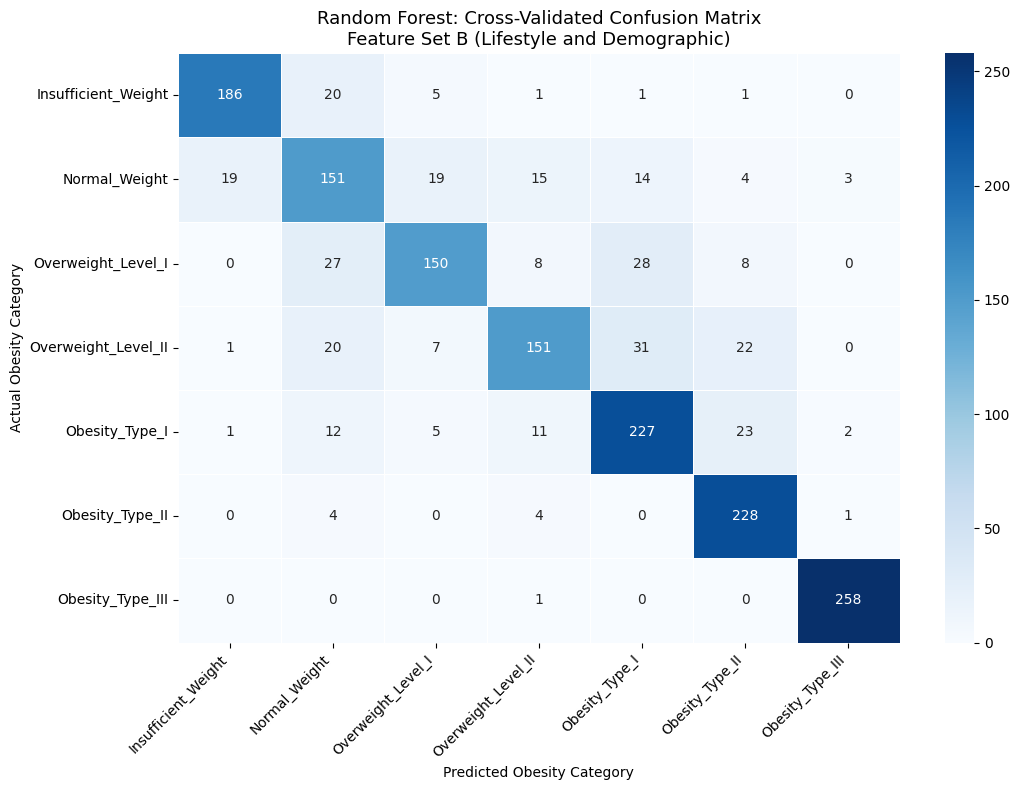

In [22]:

import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the cross-validated confusion matrix
plt.figure(figsize=(11, 8))

sns.heatmap(
    cm_df,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title(
    "Random Forest: Cross-Validated Confusion Matrix\n"
    "Feature Set B (Lifestyle and Demographic)",
    fontsize=13
)

plt.xlabel("Predicted Obesity Category")
plt.ylabel("Actual Obesity Category")

plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)

plt.tight_layout()
plt.savefig(
    "/kaggle/working/random_forest_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [23]:

from sklearn.base import clone
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

# Fit selected model using training data only
final_model = clone(rf_model)

final_model.fit(
    X_train[features_B],
    y_train
)

# Predict once on the held-out test set
test_predictions = final_model.predict(
    X_test[features_B]
)

print("Final held-out test evaluation")
print("Test observations:", len(y_test))

print("Test accuracy:",
      round(accuracy_score(y_test, test_predictions), 4))

print("Test balanced accuracy:",
      round(balanced_accuracy_score(y_test, test_predictions), 4))

print("Test macro-F1:",
      round(f1_score(y_test, test_predictions, average="macro"), 4))

print("\nTest classification report:")
print(classification_report(
    y_test,
    test_predictions,
    digits=3
))


Final held-out test evaluation
Test observations: 418
Test accuracy: 0.8014
Test balanced accuracy: 0.7978
Test macro-F1: 0.7931

Test classification report:
                     precision    recall  f1-score   support

Insufficient_Weight      0.857     0.906     0.881        53
      Normal_Weight      0.689     0.737     0.712        57
     Obesity_Type_I      0.767     0.800     0.783        70
    Obesity_Type_II      0.784     0.967     0.866        60
   Obesity_Type_III      1.000     0.985     0.992        65
 Overweight_Level_I      0.792     0.691     0.738        55
Overweight_Level_II      0.690     0.500     0.580        58

           accuracy                          0.801       418
          macro avg      0.797     0.798     0.793       418
       weighted avg      0.799     0.801     0.796       418

